# Dataset audit · Detection-reliability Active Learning

**Supporting notebook** for [Deliverable 01: Main Active Learning experiment](01_active_learning_tracking_reliability.ipynb).

**Purpose:** verify that HABBOF YOLO-OBB + ByteTrack predictions are aligned with actual WEPDTOF GT oriented boxes, inspect the label distribution, ensure all 11 input features are prediction-only, and document temporal partitioning. The target is **one predicted box per frame**, not a complete trajectory or an ID-switch event. No artificial detection/ID errors or synthetic labels are used.


In [1]:
from pathlib import Path
import json, sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import average_precision_score
from IPython.display import display

ROOT=Path.cwd()
if not (ROOT/'src').exists(): ROOT=ROOT.parent
assert (ROOT/'src').exists(), 'Launch notebook from repo root or active_learning/'
sys.path.insert(0,str(ROOT/'src'))
from reliability_al.data import FEATURES
FULL_PATH=ROOT/'data/real/repair_store_reliability.csv.gz'
PILOT_PATH=ROOT/'data/pilot/repair_store_first18_reliability.csv.gz'
DATA_MODE='full' if FULL_PATH.exists() else 'pilot'
DATA_PATH=FULL_PATH if DATA_MODE=='full' else PILOT_PATH
d=pd.read_csv(DATA_PATH)
meta=json.loads(DATA_PATH.with_suffix('').with_suffix('.metadata.json').read_text())
print('DATA MODE:', DATA_MODE.upper())
print('Dataset:', DATA_PATH.relative_to(ROOT))
print('Annotated GT frames:',meta['annotated_frames'],'/',meta['prediction_frames'])
print('GT matcher:',meta['matching'])
print('Source provenance:',meta['source'])
if DATA_MODE!='full': print('NOT FINAL: run on yourAI and save full-data notebook outputs')


DATA MODE: FULL
Dataset: data/real/repair_store_reliability.csv.gz
Annotated GT frames: 947 / 947
GT matcher: one-to-one OBB IoU >= 0.5, maximum valid assignments first
Source provenance: real_habbof_bytetrack_predictions_and_wepdtof_annotations


## 1 · How the labels are constructed

Each row in tracks.csv represents one detected person in one video frame. The five values cx, cy, width, height, and angle_radians in tracks.csv define the OBB. Predicted oriented bounding boxes (OBBs) from tracks.csv are compared with the corresponding WEPDTOF ground-truth annotations from the same video frame. OpenCV calculates the overlap between rotated bounding boxes using Intersection over Union (IoU). 

Predictions are matched to ground-truth boxes using the Hungarian assignment algorithm, with a minimum IoU threshold of 0.50. 

Successfully matched predictions receive label 1, while unmatched predictions receive label 0.

For each predicted Oriented Bounding Box (OBB):
1. Find the corresponding WEPDTOF ground-truth annotations from the same frame.
2. Calculate the oriented IoU between the predicted OBB and ground-truth OBBs.
3. Apply one-to-one Hungarian matching.
4. Assign label 1 if successfully matched at IoU ≥ 0.50; otherwise assign 0.

## 2 · 947-frames class balance and temporal partitions

Total **13,123 predictions**, including **8,473 unmatched** and **4,650 matched**. 

| Full Repair Store partition | Unmatched (0) | Matched (1) | Total |
|---|---:|---:|---:|
| Training (frames 1–620) | 5,834 | 2,974 | 8,808 |
| Excluded (frames 621–699) | 794 | 401 | 1,195 |
| Held-out test (frames 700–947) | 1,845 | 1,275 | 3,120 |
| **Total** | **8,473** | **4,650** | **13,123** |

Training is **frames 1–620**, frames **621–699** are excluded as a 79-frame gap, and testing uses **700–947**. This provides a temporal separation but is **not cross-scene generalization**.


label,GT-unmatched (0),GT-matched (1)
split,,
excluded,794,401
test,1845,1275
train,5834,2974


Actual loaded rows: 13123
Unmatched predictions: 8473
Matched predictions: 4650
Unique frames in loaded predictions: 947


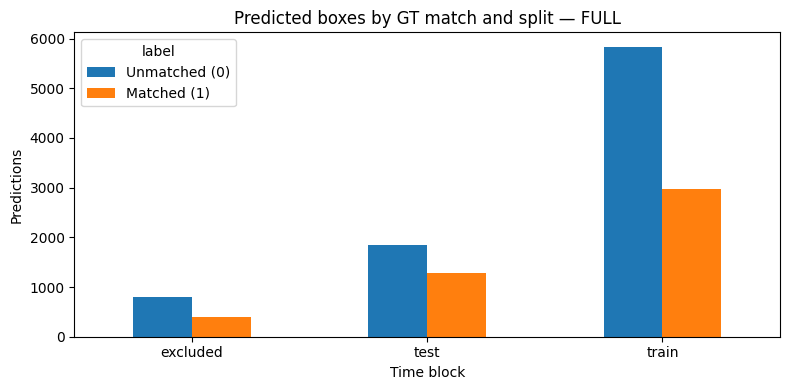

In [2]:
table=d.groupby(['split','label']).size().unstack(fill_value=0)
display(table.rename(columns={0:'GT-unmatched (0)',1:'GT-matched (1)'}))
print('Actual loaded rows:', len(d))
print('Unmatched predictions:', int(d.label.eq(0).sum()))
print('Matched predictions:', int(d.label.eq(1).sum()))
print('Unique frames in loaded predictions:',d.frame.nunique())
assert d.label.isin([0,1]).all()
assert d.loc[d.label.eq(1),'matched_iou'].ge(0.5-1.e-6).all()
assert d.loc[d.label.eq(0),'matched_iou'].isna().all()
if DATA_MODE=='full':
    assert len(d)==13123 and int(d.label.eq(1).sum())==4650, 'Cluster data does not match reported 25 Nov run; investigate rather than overwriting the report.'
fig,ax=plt.subplots(figsize=(8,4))
table.rename(columns={0:'Unmatched (0)',1:'Matched (1)'}).plot(kind='bar',ax=ax)
ax.set(title=f'Predicted boxes by GT match and split — {DATA_MODE.upper()}',ylabel='Predictions',xlabel='Time block')
ax.tick_params(axis='x', rotation=0)
fig.tight_layout()
out=ROOT/('results/full/label_counts.png' if DATA_MODE=='full' else 'results/pilot/label_counts.png')
out.parent.mkdir(parents=True,exist_ok=True)
fig.savefig(out,dpi=170,bbox_inches='tight')
display(fig)
plt.close(fig)


## 3 · Inputs, label leakage and temporal feature checks## 3. Input Features, Label Leakage, and Temporal Dependencies
In data.py, we convert each detection from tracks.csv into 11 numbers.


| Feature Group | Features | Number of Features |
|---|---|---:|
| Detection features | `confidence`, `log_area`, `aspect` | 3 |
| Tracking-history features | `age`, `gap`, `speed`, `size_change`, `angle_change`, `has_history` | 6 |
| Neighboring-box features | `nearest_distance`, `max_overlap` | 2 |
| **Total** | **numerical input features** | **11** |

These features help the Logistic Regression classifier predict whether a detection matches a ground-truth bounding box.

**Label leakage is prevented** by excluding ground-truth information, matching IoU values, labels, frame indices, and numeric track IDs from the classifier inputs. During Active Learning, sampling strategies access unlabeled features, while labels are revealed only after examples are selected, simulating human annotation.

The `max_overlap` feature uses axis-aligned boxes to measure overlap between neighboring predictions, whereas ground-truth labels are generated using oriented-box IoU.

Tracking features use observations from earlier frames, reflecting normal ByteTrack operation. However, because training and testing use different portions of the same Repair Store recording, temporal correlations may remain. Therefore, the results demonstrate performance on held-out frames rather than generalization to new environments.



In [3]:
print('Classifier feature vector (11):',FEATURES)
print('Unique event IDs:',d.event_id.is_unique)
print('Missing input values:',d[FEATURES].isna().sum().to_dict())
print('Missing labels:',int(d.label.isna().sum()))
assert len(FEATURES)==11 and d.event_id.is_unique
assert not set(FEATURES) & {'label','person_id','matched_gt_person_id','matched_iou','track_id','frame','filename','event_id'}
assert d.groupby('split').frame.agg(['min','max']).shape[0]>=2
display(d.groupby('label')[['confidence','speed','size_change','nearest_distance']].median().round(4))


Classifier feature vector (11): ['confidence', 'log_area', 'aspect', 'age', 'gap', 'speed', 'size_change', 'angle_change', 'nearest_distance', 'max_overlap', 'has_history']
Unique event IDs: True
Missing input values: {'confidence': 0, 'log_area': 0, 'aspect': 0, 'age': 0, 'gap': 0, 'speed': 0, 'size_change': 0, 'angle_change': 0, 'nearest_distance': 0, 'max_overlap': 0, 'has_history': 0}
Missing labels: 0


,confidence,speed,size_change,nearest_distance
label,,,,
0,0.4035,0.0020,0.0043,1.5267
1,0.8496,0.0026,0.0051,0.6350


## 4. Confidence-Only Baseline and Evaluation

To determine whether our 11-feature reliability classifier provides an improvement over YOLO's existing confidence score, we introduce a **confidence-only baseline**.

YOLO assigns a confidence score to each detected person. We calculate `1 - confidence` as a simple measure of potential unreliability: detections with lower confidence receive higher scores. This baseline requires no additional model training.

We compare this approach with our Logistic Regression classifier, which uses 11 detection, tracking-history, and neighboring-box features.

Performance is measured using **Average Precision (AP)**, treating unmatched detections (`label = 0`) as the positive evaluation class. Although Logistic Regression predicts the probability of a matched detection (`label = 1`), we use the corresponding unmatched probability for evaluation.

AP measures how effectively a method ranks unmatched detections ahead of matched ones across different decision thresholds. **A high AP does not mean that the same percentage of detections is correct or incorrect.** Furthermore, unmatched detections are defined by our ground-truth matching procedure, not necessarily by the absence of a real person.

This comparison helps determine whether the additional tracking features provide useful information beyond YOLO's confidence score alone.


In [4]:
test=d[d.split=='test']
baseline=(test.label==0).mean()
conf_ap=average_precision_score(1-test.label.to_numpy(),1-test.confidence.to_numpy())
print('Test unmatched prevalence (chance-ranking AP reference):',round(baseline,5))
print('Confidence-only unmatched AP:',round(conf_ap,5))
print('A model must improve on useful simple baselines as well as random AL selection.')


Test unmatched prevalence (chance-ranking AP reference): 0.59135
Confidence-only unmatched AP: 0.98882
A model must improve on useful simple baselines as well as random AL selection.
